### Estimating Error on the CMB Optical Depth from Cleaning with WMAP and Planck

As a final project for the class, we will take a first pass at a problem that we need to solve for the CLASS project. CLASS aims to measure the optical depth to reionization ($\tau$) to its cosmic variance limit on 75% of the sky that CLASS measures. To do this we use low frequency data from WMAP and high frequency data from Planck to clean polarized synchrotron and dust emission, respectively, from our data at 93 GHz. We need to understand to what extent using the WMAP and Planck data limits us in achieving the goal of a cosmic-variance measurement of $\tau$. 

* Even though CLASS only measures 75% of the sky, in this project we will use all-sky maps to simplify the analysis.
* For simulations, use `camb` to generate angular power spectra given cosmological parameters and `healpy` `synfast` to generate maps from these spectra. For input cosmological parameters use those introduced in the `get_spectra` function of Lecture 5.
* Use `healpy` `anafast` to estimate auto and cross power spectra. 
* For foreground models, let's use `pysm`'s `s1` model for synchrotron and its `d1` model for dust.
* The low-$\ell$ ($\ell<32$) E-mode spectrum of the CMB polarization increases proportional to $\tau^2$. When estimating a best-fit $\tau$ you will use a likelihood built from a simulated E-mode angular power spectrum (the data) for $\ell<32$ and a model for the power spectrum generated by `camb` (Lecture 8).
* For simplicity, assume a Gaussian likelihood for the $C_\ell$ with no covariance between $C_\ell$. If there is time, we'll revisit this assumption in the light of arguments like the one in problem 3 of lecture 8.
* When fitting the model for $C_\ell$, you can hold all cosmological parameters but $\tau$ fixed to their input values (second bullet above). Because adjusting $\tau$ changes $C_\ell$, and therefore the cosmic variance, you will need to adjust the variance in your likelihood as well.
* You should be able to get away with NSIDE=32 healpix maps.

## Part 1: Estimate the Cosmic-Variance-Limit for Tau using CMB-only Maps

Create full sky simulations of the CMB with no foregrounds and no noise. Estimate the uncertainty on the best-fit $\tau$ by fitting many realizations of the CMB E-mode spectrum.

Instead of doing simulations, create a dataset that has its mean as the "true" power spectrum and assign errors corresponding to cosmic variance. Then use a Markov chain monte carlo to estimate the error on $\tau$.

### Testing individual steps

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import healpy as hp
import os
import camb
from camb import model, initialpower
from scipy.optimize import minimize
from corner import corner

pars = camb.CAMBparams()

Text(0.5, 1.0, 'True CMB EE Spectrum')

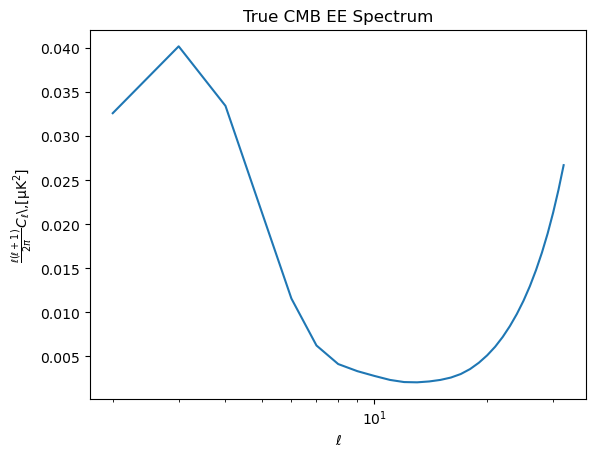

In [ ]:
lmax=32
def get_Clhat(tau, lmax=lmax, raw_cl=True,
              H0=67, Ombh2=0.024, Omch2=0.12,
              As=2.1e-9, ns=0.965, ks=0.05, 
              kt=0.05, Omk=0, TCMB=2.7255, 
              mnu=0.06, r=0, YHe=0.245400,):
    '''
    Specify tau, and use other known parameters:     The cosmological parameter assumed here are from the abstract of the Planck 2018 results paper
    https://arxiv.org/abs/1807.06209.
    '''
    pars.set_cosmology(H0=H0, ombh2=Ombh2, omch2=Omch2, mnu=mnu, omk=Omk, tau=tau, TCMB=TCMB, YHe=YHe)
    pars.InitPower.set_params(As=As, ns=ns, r=r, pivot_scalar=ks, pivot_tensor=kt)
    results = camb.get_results(pars)
    powers = results.get_total_cls(lmax=lmax, CMB_unit='muK', raw_cl=True)
    TT, EE, BB, TE = powers.T
    #ls = np.arange(2, EE.shape[0]) # could add??
    return np.array([TT, EE, BB, TE])

true_tau = 0.054
ls = np.arange(2, lmax+1)
true_spectra = get_Clhat(true_tau) # ensemble average power spectrum
Z = ls*(ls+1)/(2*np.pi)
plt.semilogx(ls, true_spectra[1][ls]*Z)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell$\,$\mathrm{[\mu K^2]}$')
plt.title("True CMB EE Spectrum")

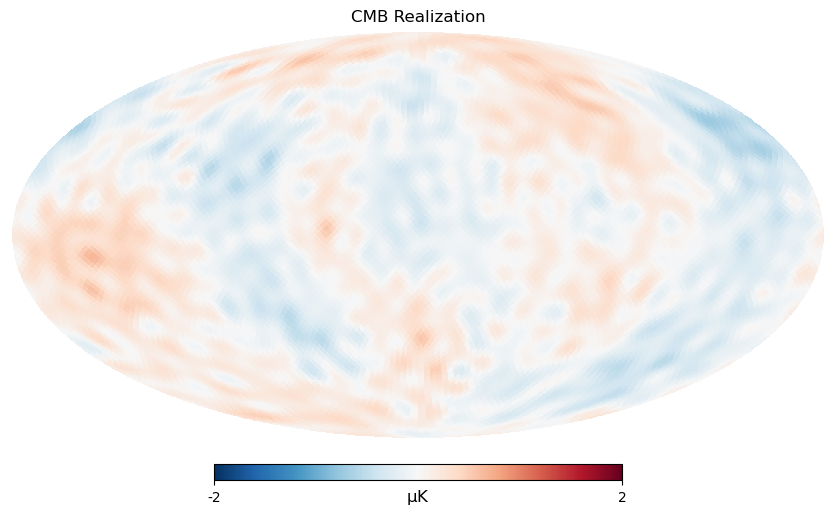

In [3]:
nside=32

# power spectra -> map with random realization of Cl (random alm)
s = hp.synfast(true_spectra, nside, lmax=lmax, new=True)
almT,almE,almB = hp.map2alm(s,lmax=lmax)
E_map = hp.alm2map(almE, nside)
hp.mollview(E_map, min=-2, max=2, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='CMB Realization', xsize=2000)

Text(0, 0.5, '$\\ell(\\ell+1)C_\\ell/2\\pi$ [$\\mathrm{\\mu K^2}$]')

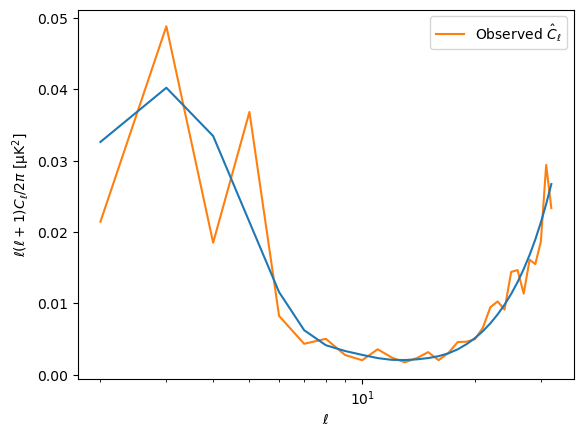

In [4]:
# random map -> Clhat
# Clhat = hp.anafast(E_map)
Clhats = hp.anafast(s, lmax=lmax)
Clhat = Clhats[1]

plt.semilogx(ls, true_spectra[1][ls]*Z)
plt.semilogx(ls, Clhat[ls]*Z, label=r'Observed $\hat C_\ell$', zorder=-1)
#plt.ylim(ymin=1e1)*
plt.legend(loc='best')
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\ell(\ell+1)C_\ell/2\pi$ [$\mathrm{\mu K^2}$]')

In [5]:
# finding best fit tau for Clhat by minimizing chi square

def make_chi2(Clhat):

    def chi2(tau):
        theory_EE = get_Clhat(tau)[1]
        cosmic_var = np.sqrt(2/(2*ls + 1))*theory_EE[ls]
        #cosmic_var = np.sqrt(2/(2*ls + 1))*true_spectra[1][ls]
        return sum(((Clhat[2:33] - theory_EE[2:33])/cosmic_var)**2 + np.log(np.sqrt(cosmic_var)))
    
    return chi2
chi2 = make_chi2(Clhat)
sol = minimize(chi2, true_tau, bounds=[(0.04, 0.2)])
print(sol.x)

[0.05631535]


### Simulations (no foreground, no noise) to find tau distribution

In [ ]:
tau_dist = []
for i in range(200):
    s = hp.synfast(true_spectra, nside, lmax=lmax, new=True)
    Clhats = hp.anafast(s, lmax=lmax)
    Clhat = Clhats[1]
    chi2 = make_chi2(Clhat)
    sol = minimize(chi2, true_tau, bounds=[(0.04, 0.2)])
    tau_dist.append(sol.x[0])
tau_dist = np.array(tau_dist)
print(tau_dist)
print(tau_dist.mean())

[0.05278761 0.05097804 0.04990264 0.05425362 0.05149604 0.04988537
 0.05450223 0.05481478 0.05517229 0.05484498 0.05503507 0.05510127
 0.05310319 0.05401791 0.05414124 0.05279805 0.05727278 0.05245338
 0.05389249 0.05387418 0.0542439  0.05895728 0.05234762 0.05362407
 0.05061115 0.05411827 0.05264295 0.05538309 0.05271952 0.0506774
 0.05150149 0.0535639  0.05311983 0.05205808 0.05578125 0.05393042
 0.05593433 0.05624933 0.05536778 0.05056862 0.05408613 0.05498555
 0.05384189 0.05567577 0.05432601 0.05456635 0.05434298 0.05077898
 0.05575628 0.05697848 0.05483369 0.05280116 0.05275111 0.05495481
 0.05398985 0.0525287  0.05864207 0.05035913 0.05138788 0.05200141
 0.05688848 0.05111449 0.05250399 0.05449271 0.05579416 0.04962569
 0.05182207 0.0520854  0.0548243  0.05386572 0.0555777  0.05759355
 0.05393048 0.05392714 0.05049029 0.05323767 0.05786626 0.05317837
 0.05413299 0.05722536 0.05121902 0.0589804  0.0569839  0.05242928
 0.05665976 0.05072722 0.05333458 0.05797052 0.05256578 0.05048

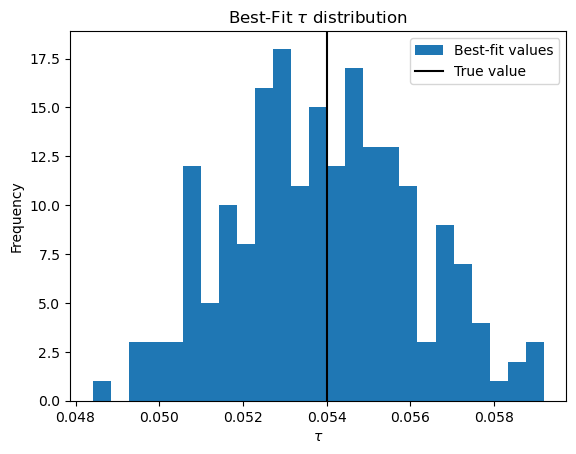

In [20]:
plt.hist(tau_dist, bins=25, density=False, label="Best-fit values")
plt.xlabel(r'$\tau$')
plt.ylabel("Frequency")
plt.title("Best-Fit "r'$\tau$' " distribution")
plt.axvline(0.054, color='black', label="True value")
# plt.axvline(0.054+tau_dist.std(), color='red')
# plt.axvline(0.054-tau_dist.std(), color='red')
plt.legend(loc='best')

In [18]:
print(tau_dist.std())
print(tau_dist.mean())

0.002160532182419194
0.053899388030734664


$$\tau = 0.054 \pm 0.002 $$

In [ ]:
tau_grid = np.linspace(0.044, 0.064, 8)

EE_grid = np.array([
    get_Clhat(t)[1]
    for t in tau_grid
])

var_grid = np.array([
    (2/(2*ls + 1))*(ee[ls])**2
    for ee in EE_grid
])

In [ ]:
tau_grid = np.linspace(0.044, 0.064, 801)
EE_coarse_grid = np.array([
    get_Clhat(t)[1]
    for t in tau_grid
])


In [35]:
tau_fine = np.linspace(0.044, 0.064, 1501)
test_tau = tau_fine[1:-1]

EE_fine = np.array([
    get_Clhat(t)[1]
    for t in tau_fine
])

In [62]:
EE_test = np.array([
    get_Clhat(t)[1]
    for t in test_tau
])

In [57]:
from scipy.interpolate import PchipInterpolator
EE_pchip = PchipInterpolator(
    tau_grid, 
    EE_coarse_grid, 
    axis=0
)
from scipy.interpolate import CubicSpline
EE_cubicspline = CubicSpline(
    tau_grid, 
    EE_coarse_grid, 
    axis=0
)

In [42]:
from scipy.optimize import minimize_scalar

In [58]:

def run_simulation_grid(nsim):
    tau_dist_coarse = []
    tau_dist_pchip = []
    tau_dist_cubic_spline = []
    tau_dist_fine = []

    log_var_grid_coarse = np.log(2*np.pi*var_grid_coarse)
    log_var_grid_pchip = np.log(2*np.pi*var_grid_pchip)
    log_var_grid_cubic_spline = np.log(2*np.pi*var_grid_cubic_spline)
    log_var_grid_fine = np.log(2*np.pi*var_grid_fine)

    for i in range(nsim):
        s = hp.synfast(true_spectra, nside, lmax=lmax, new=True)

        Clhat = hp.anafast(s, lmax=lmax)[1]

        chi2 = np.sum(
            ((Clhat[None, 2:33] - EE_coarse_grid[:, 2:33])**2 / var_grid_coarse) + log_var_grid_coarse,
            axis=1
        )
        tau_dist_coarse.append(tau_grid[np.argmin(chi2)])

        chi2 = np.sum(
            ((Clhat[None, 2:33] - EE_pchip(tau_fine)[:, 2:33])**2 / var_grid_pchip) + log_var_grid_pchip,
            axis=1
        )
        tau_dist_pchip.append(tau_fine[np.argmin(chi2)])

        chi2 = np.sum(
            ((Clhat[None, 2:33] - EE_cubicspline(tau_fine)[:, 2:33])**2 / var_grid_cubic_spline) + log_var_grid_cubic_spline,
            axis=1
        )
        tau_dist_cubic_spline.append(tau_fine[np.argmin(chi2)])

        chi2 = np.sum(
            ((Clhat[None, 2:33] - EE_fine[:, 2:33])**2 / var_grid_fine) + log_var_grid_fine,
            axis=1
        )
        tau_dist_fine.append(tau_fine[np.argmin(chi2)])

    return np.array(tau_dist_coarse), np.array(tau_dist_pchip), np.array(tau_dist_cubic_spline), np.array(tau_dist_fine)

In [46]:
var_grid_coarse = np.array([
    (2/(2*ls + 1))*(ee[ls])**2
    for ee in EE_coarse_grid
])
var_grid_pchip = np.array([
    (2/(2*ls + 1))*(ee[ls])**2
    for ee in EE_pchip(tau_fine)
])
var_grid_cubic_spline = np.array([
    (2/(2*ls + 1))*(ee[ls])**2
    for ee in EE_cubicspline(tau_fine)
])
var_grid_fine = np.array([
    (2/(2*ls + 1))*(ee[ls])**2
    for ee in EE_fine
])

tau_dist_orig, tau_dist_pchip, tau_dist_cubic_spline, tau_dist_fine = run_simulation_grid(1000)

Text(0.5, 1.0, 'Fine grid: 1501 tau values')

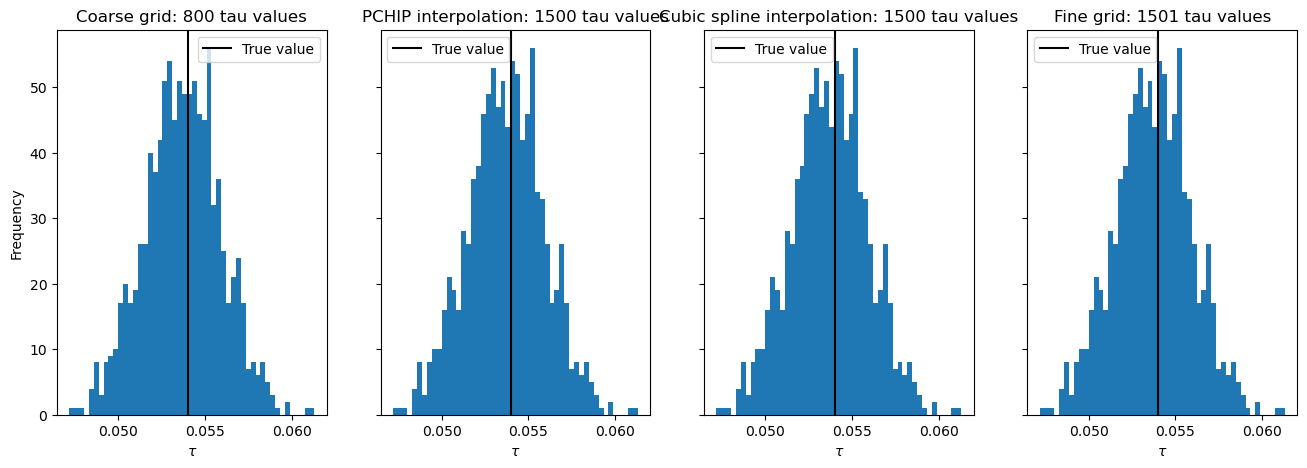

In [48]:

fig, ax = plt.subplots(1,4, figsize=(16,5), sharey=True)
ax = ax.flatten()
for i, tau_dist in enumerate([tau_dist_orig, tau_dist_pchip, tau_dist_cubic_spline, tau_dist_fine]):
    ax[i].hist(tau_dist, bins=50, density=False)
    ax[i].set_xlabel(r'$\tau$')
    ax[i].axvline(0.054, color='black', label="True value")
    ax[i].legend(loc='best')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Coarse grid: 800 tau values")
ax[1].set_title("PCHIP interpolation: 1500 tau values")
ax[2].set_title("Cubic spline interpolation: 1500 tau values")
ax[3].set_title("Fine grid: 1501 tau values")

In [51]:
print(f"{'Method':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Coarse grid':<28} {tau_dist_orig.std():>12.10f} {tau_dist_orig.mean():>12.10f}")
print(f"{'PCHIP interpolation':<28} {tau_dist_pchip.std():>12.10f} {tau_dist_pchip.mean():>12.10f}")
print(f"{'Cubic spline interpolation':<28} {tau_dist_cubic_spline.std():>12.10f} {tau_dist_cubic_spline.mean():>12.10f}")
print(f"{'Fine grid':<28} {tau_dist_fine.std():>12.10f} {tau_dist_fine.mean():>12.10f}")

Method                                Std         Mean
------------------------------------------------------
Coarse grid                  0.0021686015 0.0537157000
PCHIP interpolation          0.0021683698 0.0537159467
Cubic spline interpolation   0.0021683698 0.0537159467
Fine grid                    0.0021683878 0.0537159600


In [52]:
tau_grid = np.linspace(0.044, 0.064, 51)
EE_coarse_grid = np.array([
    get_Clhat(t)[1]
    for t in tau_grid
])

In [59]:
var_grid_coarse = np.array([
    (2/(2*ls + 1))*(ee[ls])**2
    for ee in EE_coarse_grid
])
var_grid_pchip = np.array([
    (2/(2*ls + 1))*(ee[ls])**2
    for ee in EE_pchip(tau_fine)
])
var_grid_cubic_spline = np.array([
    (2/(2*ls + 1))*(ee[ls])**2
    for ee in EE_cubicspline(tau_fine)
])
var_grid_fine = np.array([
    (2/(2*ls + 1))*(ee[ls])**2
    for ee in EE_fine
])

tau_dist_orig, tau_dist_pchip, tau_dist_cubic_spline, tau_dist_fine = run_simulation_grid(1000)

Text(0.5, 1.0, 'Fine grid: 1500 tau values')

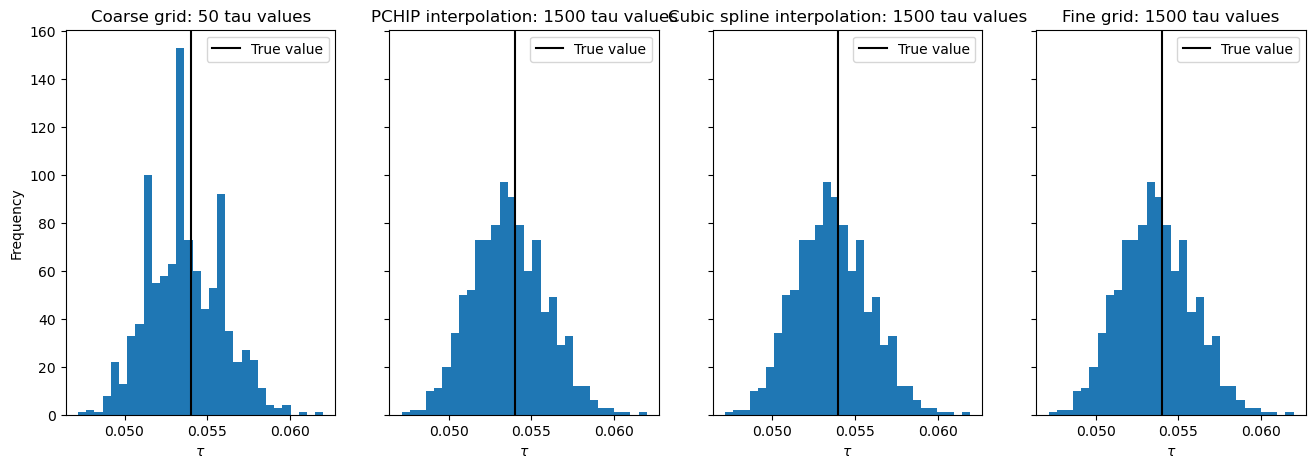

In [60]:
fig, ax = plt.subplots(1,4, figsize=(16,5), sharey=True)
ax = ax.flatten()
for i, tau_dist in enumerate([tau_dist_orig, tau_dist_pchip, tau_dist_cubic_spline, tau_dist_fine]):
    ax[i].hist(tau_dist, bins=30, density=False)
    ax[i].set_xlabel(r'$\tau$')
    ax[i].axvline(0.054, color='black', label="True value")
    ax[i].legend(loc='best')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Coarse grid: 50 tau values")
ax[1].set_title("PCHIP interpolation: 1500 tau values")
ax[2].set_title("Cubic spline interpolation: 1500 tau values")
ax[3].set_title("Fine grid: 1500 tau values")

In [61]:
print(f"{'Method':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Coarse grid':<28} {tau_dist_orig.std():>12.10f} {tau_dist_orig.mean():>12.10f}")
print(f"{'PCHIP interpolation':<28} {tau_dist_pchip.std():>12.10f} {tau_dist_pchip.mean():>12.10f}")
print(f"{'Cubic spline interpolation':<28} {tau_dist_cubic_spline.std():>12.10f} {tau_dist_cubic_spline.mean():>12.10f}")
print(f"{'Fine grid':<28} {tau_dist_fine.std():>12.10f} {tau_dist_fine.mean():>12.10f}")

Method                                Std         Mean
------------------------------------------------------
Coarse grid                  0.0022118942 0.0536380000
PCHIP interpolation          0.0022049879 0.0536420000
Cubic spline interpolation   0.0022050502 0.0536419467
Fine grid                    0.0022050502 0.0536419467


### interpolating from 800 to 1000

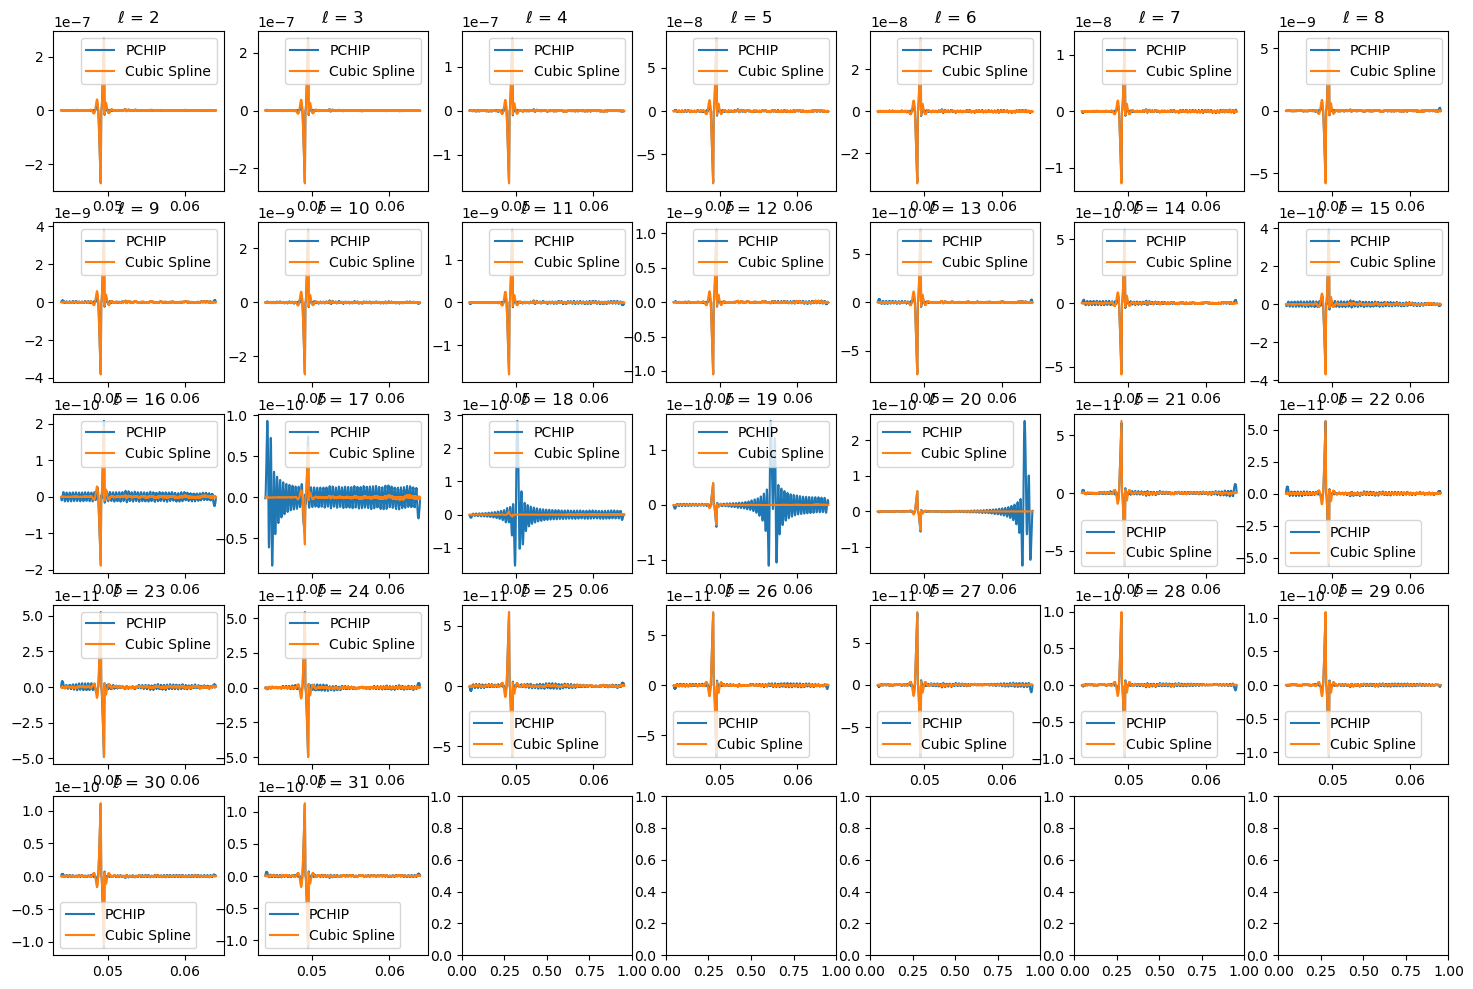

In [63]:
fig, ax = plt.subplots(5, 7, figsize=(18, 12))
ax = ax.flatten()
for i,l in enumerate(ls[:-1]):
    
    ax[i].plot(test_tau, EE_pchip(test_tau)[:, l]-EE_test[:,l], label="PCHIP")
    ax[i].plot(test_tau, EE_cubicspline(test_tau)[:, l]-EE_test[:,l], label="Cubic Spline")
    ax[i].set_title(r"$\ell$ = {}".format(l))
    ax[i].legend()

In [32]:
tau_dist = run_simulation_grid(801, 1000)

In [33]:
print(tau_dist.mean(), tau_dist.std())

0.05370995 0.0022340360891221077


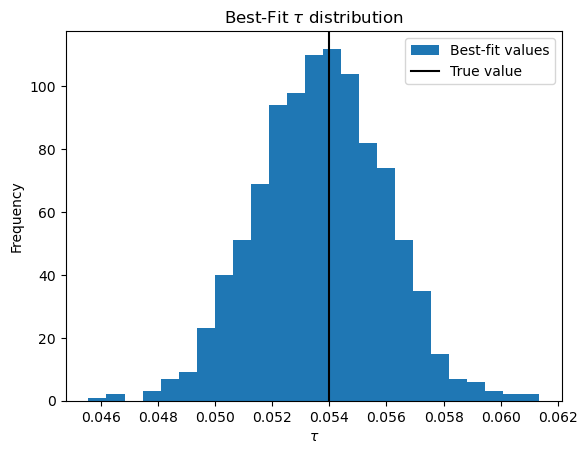

In [34]:
plt.hist(tau_dist, bins=25, density=False, label="Best-fit values")
plt.xlabel(r'$\tau$')
plt.ylabel("Frequency")
plt.title("Best-Fit "r'$\tau$' " distribution")
plt.axvline(0.054, color='black', label="True value")
# plt.axvline(0.054+tau_dist.std(), color='red')
# plt.axvline(0.054-tau_dist.std(), color='red')
plt.legend(loc='best')

## FULL CODE

In [ ]:
lmax = 32
nside = 32
def get_Clhat(tau, lmax=lmax, raw_cl=True,
              H0=67, Ombh2=0.024, Omch2=0.12,
              As=2.1e-9, ns=0.965, ks=0.05, 
              kt=0.05, Omk=0, TCMB=2.7255, 
              mnu=0.06, r=0, YHe=0.245400,):
    '''
    Specify tau, and use other known parameters:     The cosmological parameter assumed here are from the abstract of the Planck 2018 results paper
    https://arxiv.org/abs/1807.06209.
    '''
    pars.set_cosmology(H0=H0, ombh2=Ombh2, omch2=Omch2, mnu=mnu, omk=Omk, tau=tau, TCMB=TCMB, YHe=YHe)
    pars.InitPower.set_params(As=As, ns=ns, r=r, pivot_scalar=ks, pivot_tensor=kt)
    results = camb.get_results(pars)
    powers = results.get_total_cls(lmax=lmax, CMB_unit='muK', raw_cl=True)
    TT, EE, BB, TE = powers.T
    #ls = np.arange(2, EE.shape[0]) # could add??
    return np.array([TT, EE, BB, TE])

true_tau = 0.054
ls = np.arange(2, lmax+1)
true_spectra = get_Clhat(true_tau) # ensemble average power spectrum

#w_pT, w_pP = hp.pixwin(nside, pol=True, lmax=lmax)

tau_coarse_grid = np.linspace(0.044, 0.064, 100)

EE_coarse_grid = np.array([
    get_Clhat(t)[1]
    for t in tau_coarse_grid
])

from scipy.interpolate import CubicSpline
EE_cubicspline = CubicSpline(
    tau_coarse_grid, 
    EE_coarse_grid, 
    axis=0
)

tau_grid = np.linspace(0.044, 0.064, 500)

EE_grid = EE_cubicspline(tau_grid)# * w_pP**2

var_grid = (2/(2*ls + 1))[None, :] * (EE_grid[:, ls])**2 

log_var_grid = np.log(2*np.pi*var_grid)

tau_dist = []

nsim = 500

for i in range(nsim):
    s = hp.synfast(true_spectra, nside, lmax=lmax, new=True)

    Clhat = hp.anafast(s, lmax=lmax, use_pixel_weights=True)[1]

    # chi2 = np.sum(
    #     ((Clhat[None, 2:33] - EE_grid[:, 2:33])**2 / var_grid) + log_var_grid,
    #     axis=1
    # )
    chi2 = np.sum(
        ((Clhat[ls][None, :] - EE_grid[:, ls])**2 / var_grid) + log_var_grid,
        axis=1
    )
    tau_dist.append(tau_grid[np.argmin(chi2)])
    #tau_dist.append(np.mean(Clhat[2:] / true_spectra[1][2:], axis=0))

tau_dist = np.array(tau_dist)

In [36]:
tau_dist = []

nsim = 500

for i in range(nsim):
    s = hp.synfast(true_spectra, nside, lmax=lmax, new=True, pixwin=True)

    Clhat = hp.anafast(s, lmax=lmax)[1]

    x = (Clhat[ls][None, :]/EE_grid[:, ls])

    chi2 = np.sum(
        (2*ls+1)*(x - np.log(x) - 1),
        axis=1
    )
    tau_dist.append(tau_grid[np.argmin(chi2)])
    #tau_dist.append(np.mean(Clhat[2:] / true_spectra[1][2:], axis=0))

tau_dist = np.array(tau_dist)

In [12]:
EE_grid = EE_cubicspline(tau_grid) * w_pP**2

In [37]:
print(f"{'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{np.std(tau_dist):>12.6f} {np.mean(tau_dist):>12.6f}")

         Std         Mean
------------------------------------------------------
    0.002095     0.053679


In [34]:
var_grid = np.array([
    (2/(2*ls + 1))*(ee[ls])**2
    for ee in EE_grid
])
print(var_grid)

var_grid = (2/(2*ls + 1))[None, :] * (EE_grid[:, ls])**2 

[[2.96856859e-04 6.15696805e-05 9.00076598e-06 ... 7.07406994e-10
  7.55516427e-10 8.06337361e-10]
 [2.97475971e-04 6.17759322e-05 9.04262957e-06 ... 7.07294823e-10
  7.55404406e-10 8.06223714e-10]
 [2.98095610e-04 6.19826098e-05 9.08463568e-06 ... 7.07182711e-10
  7.55292437e-10 8.06110071e-10]
 ...
 [6.59606471e-04 2.18503365e-04 5.24073707e-05 ... 6.58156065e-10
  7.02454627e-10 7.48346368e-10]
 [6.60430753e-04 2.18930594e-04 5.25496208e-05 ... 6.58082601e-10
  7.02362931e-10 7.48238119e-10]
 [6.61255357e-04 2.19358269e-04 5.26921245e-05 ... 6.58009298e-10
  7.02271349e-10 7.48129939e-10]]


In [35]:
print(var_grid)

[[2.96856859e-04 6.15696805e-05 9.00076598e-06 ... 7.07406994e-10
  7.55516427e-10 8.06337361e-10]
 [2.97475971e-04 6.17759322e-05 9.04262957e-06 ... 7.07294823e-10
  7.55404406e-10 8.06223714e-10]
 [2.98095610e-04 6.19826098e-05 9.08463568e-06 ... 7.07182711e-10
  7.55292437e-10 8.06110071e-10]
 ...
 [6.59606471e-04 2.18503365e-04 5.24073707e-05 ... 6.58156065e-10
  7.02454627e-10 7.48346368e-10]
 [6.60430753e-04 2.18930594e-04 5.25496208e-05 ... 6.58082601e-10
  7.02362931e-10 7.48238119e-10]
 [6.61255357e-04 2.19358269e-04 5.26921245e-05 ... 6.58009298e-10
  7.02271349e-10 7.48129939e-10]]


## Part 1.2

In [ ]:
def log_posterior(tau, ell, theory_EE):
    return log_like(tau, ell, theory_EE) + log_prior(tau, ell)

def log_like(tau, ell, theory_EE):
    var = 2/(2*ell + 1)*theory_EE[ell]**2
    chi2 = np.sum(((true_spectra[1][ell] - theory_EE[ell]))**2/var)
    lndet = sum(np.log(2*np.pi*var))
    return -0.5*chi2 - 0.5*lndet

def log_prior(tau, ell):
    # Using a flat prior for simplicity - pdf = 1 without normalization
    # if (tau < 0.04) or (tau > 0.2):
    if tau < 0:
        return -np.inf
    else:
        return 0

In [8]:
ls = np.arange(lmax+1)
cosmic_var = np.sqrt(2/(2*ls + 1))*true_spectra[1][ls]

In [15]:
from numpy.random import default_rng
seed = 137
rng = default_rng(seed)

nsteps = 2000
chain = np.zeros((nsteps, len(sol.x)))
guess = 0.054
chain[0] = guess #sol.x

ell = np.arange(2, lmax+1)
for t in range(1,nsteps):
    x_test = rng.standard_normal()*0.003 + chain[t-1]
    theory_new = get_Clhat(x_test)[1]
    theory_old = get_Clhat(chain[t-1])[1]
    A = np.exp(log_posterior(x_test,ell,theory_new) - log_posterior(chain[t-1],ell, theory_old))
    accept = (A > rng.random())
    if accept:
        chain[t] = x_test
    else:
        chain[t] = chain[t-1]
    if t % 100 == 0:
        print(t)
print("done")

100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
done


In [16]:
# Acceptance fraction estimation
print(np.unique(chain).size/chain.size)

0.6055


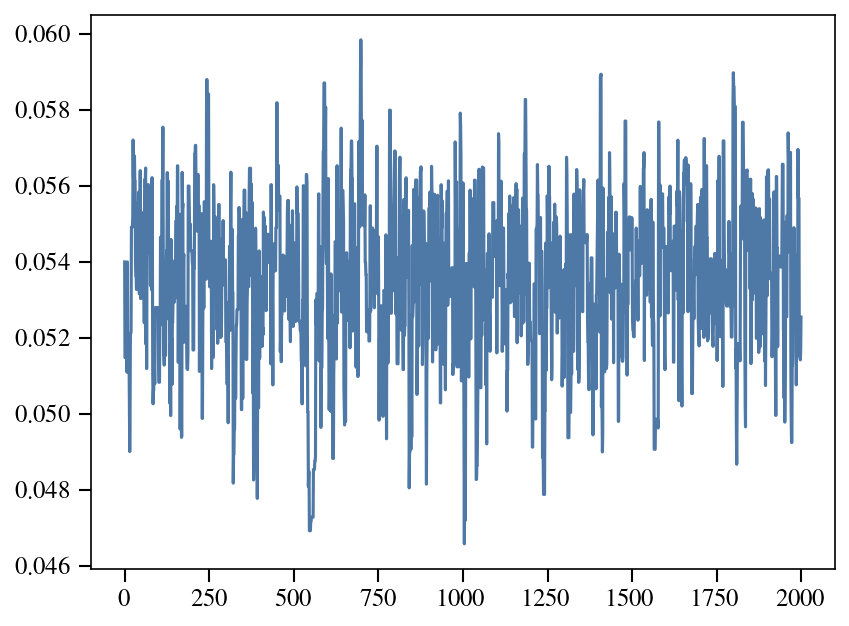

In [17]:
plt.plot(chain)

(array([  1.,   4.,  10.,   0.,   5.,   3.,   4.,  10.,  11.,  13.,  13.,
         10.,  29.,  25.,  14.,  28.,  27.,  68.,  64.,  51.,  80.,  73.,
         97., 102., 103., 114.,  89.,  92., 102., 113.,  86., 102.,  69.,
         70.,  80.,  49.,  52.,  41.,  30.,  16.,   6.,  11.,   2.,  12.,
          6.,   5.,   6.,   1.,   0.,   1.]),
 array([0.04657566, 0.04684116, 0.04710667, 0.04737217, 0.04763768,
        0.04790319, 0.04816869, 0.0484342 , 0.0486997 , 0.04896521,
        0.04923072, 0.04949622, 0.04976173, 0.05002723, 0.05029274,
        0.05055825, 0.05082375, 0.05108926, 0.05135476, 0.05162027,
        0.05188578, 0.05215128, 0.05241679, 0.05268229, 0.0529478 ,
        0.0532133 , 0.05347881, 0.05374432, 0.05400982, 0.05427533,
        0.05454083, 0.05480634, 0.05507185, 0.05533735, 0.05560286,
        0.05586836, 0.05613387, 0.05639938, 0.05666488, 0.05693039,
        0.05719589, 0.0574614 , 0.05772691, 0.05799241, 0.05825792,
        0.05852342, 0.05878893, 0.05905444, 0.

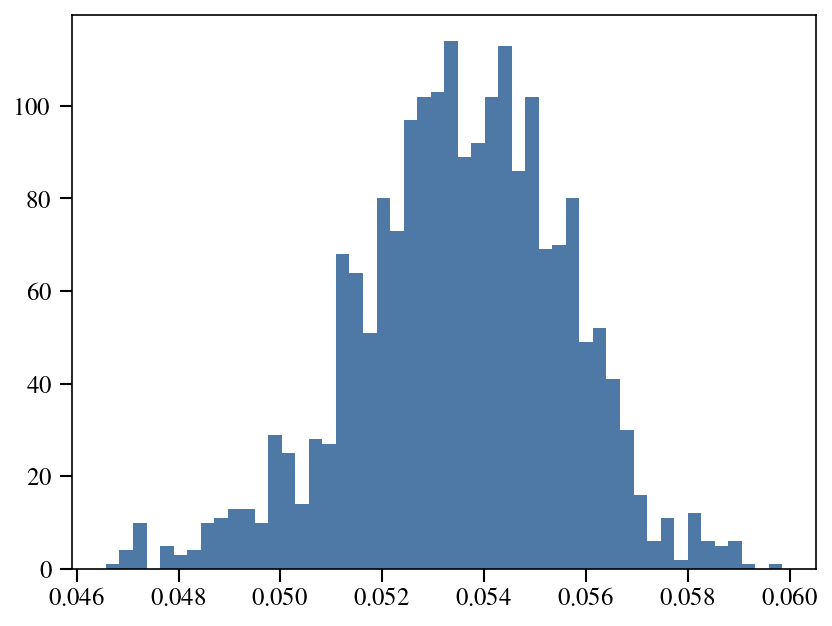

In [18]:
plt.hist(chain, bins=50)

TypeError: object of type 'float' has no len()

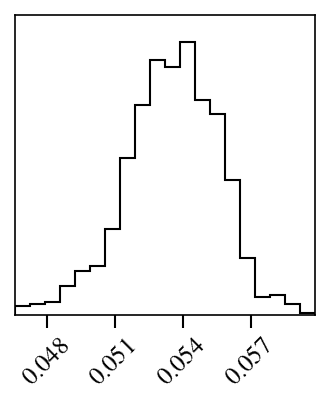

In [19]:
fig = corner(chain, discard=100, truths=guess)

In [21]:
print(chain.std())
print(chain.mean())

0.0020647375651911258
0.05353923179360537


$$ \tau = 0.054 \pm 0.002 $$

In [47]:
# trying emcee

import emcee

def log_posterior_mc(theta, ell):
    tau = theta[0]
    theory_EE = get_Clhat(tau)[1]
    return log_like(tau, ell, theory_EE) + log_prior(tau, ell)

pos = guess +  rng.standard_normal((4, len(sol.x)))*0.005
nwalkers, ndim = pos.shape

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior_mc, args=(ell,))
sampler.run_mcmc(pos, 500, progress=True)

100%|██████████| 500/500 [08:35<00:00,  1.03s/it]


State([[0.05568981]
 [0.05300931]
 [0.05343458]
 [0.05586559]], log_prob=[272.57561729 272.82112035 272.89488726 272.49482442], blobs=None, random_state=('MT19937', array([2186926696, 1677045556, 1256178491,  374016705, 1001924814,
       3730313489, 1017359874, 1142144600, 1554384371, 2162663401,
       1786833504, 2307448427, 3465407189, 2456100830, 2069695915,
        185502752, 1377818942, 4240646507, 2073623142,  258650747,
       2985869370, 2484289225, 1519167757, 3813693173, 1449145747,
       2079437729, 1107760867, 3233164779,  558617973, 3428313432,
         21638459, 2792689719, 2898732483, 2215028078, 3629461214,
       2299112348, 2099386861, 3358874074, 2743432298,  948036809,
       3289359965, 2930595099, 2150904807,  378406181,  867471022,
       3418165872, 3620844142, 1119134256, 2092474065, 1774595763,
       1244496359,  701960325, 3657734045, 2636502012, 2369319068,
       2495308880, 3171200899,  152913935, 1594845704, 3717090039,
        386922602, 4197252885, 

(500, 4, 1)


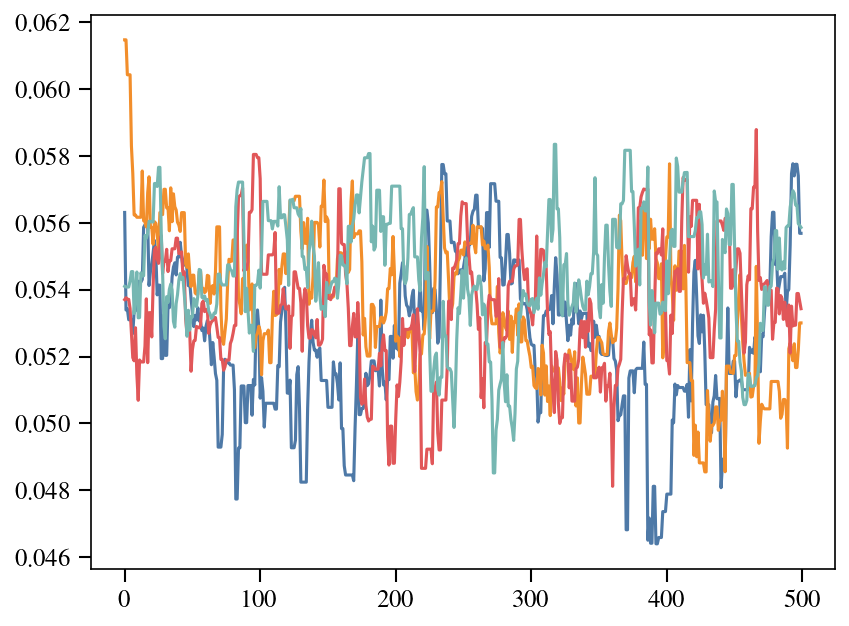

In [48]:
samples = sampler.get_chain()
print(samples.shape)
plt.plot(samples[:, :, 0])

In [49]:
print(sampler.acceptance_fraction)

[0.764 0.792 0.806 0.788]


TypeError: object of type 'float' has no len()

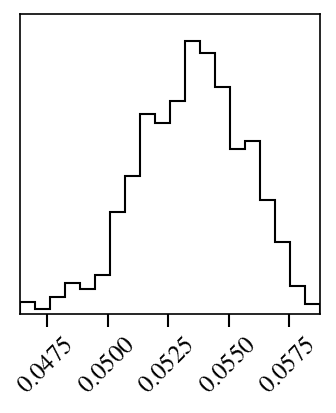

In [50]:
flat_samples = sampler.get_chain(discard = 5, flat=True)
fig = corner(flat_samples,
          truths=guess)

(array([  3.,   0.,   1.,   1.,   5.,   4.,   3.,   6.,   5.,  13.,  13.,
         27.,  35.,  26.,  27.,  22.,  46.,  54.,  42.,  77.,  66.,  65.,
        114., 106., 114.,  91.,  97.,  97., 100.,  83.,  78.,  94.,  73.,
         75.,  56.,  44.,  52.,  35.,  25.,  20.,  32.,  28.,   6.,   7.,
          1.,   9.,   5.,   0.,   1.,   6.]),
 array([0.04685834, 0.04713359, 0.04740884, 0.04768409, 0.04795934,
        0.04823459, 0.04850984, 0.04878509, 0.04906034, 0.04933559,
        0.04961084, 0.04988609, 0.05016134, 0.05043659, 0.05071184,
        0.05098709, 0.05126234, 0.05153759, 0.05181284, 0.05208809,
        0.05236334, 0.05263859, 0.05291384, 0.05318909, 0.05346434,
        0.05373959, 0.05401484, 0.05429009, 0.05456534, 0.05484058,
        0.05511583, 0.05539108, 0.05566633, 0.05594158, 0.05621683,
        0.05649208, 0.05676733, 0.05704258, 0.05731783, 0.05759308,
        0.05786833, 0.05814358, 0.05841883, 0.05869408, 0.05896933,
        0.05924458, 0.05951983, 0.05979508, 0.

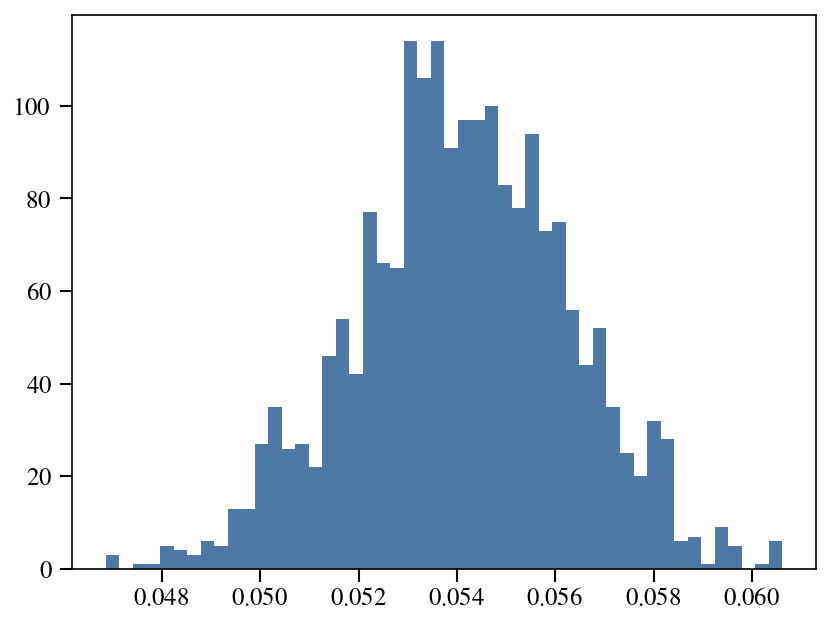

In [28]:
plt.hist(flat_samples, bins=50)

## On Mean and Variance

In order to fit the data to obtain an estimate of the value and uncertainty of $\tau$, we consider maximizing the likelihood (and therefore, the log-likelihood) using $\tau$ as the parameter.

people often think about this optimization problem as minimizing $\chi^2$, which is closely related to the log-likelihood.
$$
\mathcal L(\tau\mid y)=\prod_i \frac1{\sqrt{2\pi\sigma_i(\tau)^2}}\exp\left(-\frac{(s_i(\tau)-y_i)^2}{2\sigma_i(\tau)^2}\right)
$$
$$
\ln\mathcal L=\sum_i-\frac{(s_i(\tau)-y_i)^2}{2\sigma_i(\tau)^2}-\frac12\ln[2\pi\sigma_i(\tau)^2]
\equiv -\frac12\chi^2-\frac12\sum_i\ln(2\pi\sigma_i(\tau)^2)
$$

If the noise $\sigma_i(\tau)$ is not a free parameter, then maximizing the likelihood will give identical results to minimizing $\chi^2$.

Unfortunately for us, $\sigma_i(\tau)$ is dependent on the power spectra obtained from our parameter $\tau$.

Do not panic. We just need to include this in our function that is to be minimized.

### Part 1:

When no noise is taken into consideration, the mean and variance to be used in the log-likelihood expression are straight forward.

$$
\langle\hat C_\ell\rangle=C_\ell,\qquad
\mathrm{var}(\hat C_\ell)=\frac2{2\ell+1}C_\ell^2.
$$

Thus, to maximize the log-likelihood is to obtain the minimum value of

$$
\frac12\chi^2+\frac12\sum_i\ln(2\pi\sigma_i(\tau)^2)\equiv \boxed{\frac12\sum_\ell\frac{(C_\ell(\tau)-y_\ell)^2}{\frac{2}{2\ell+1}C_\ell(\tau)^2}+\ln[\frac{4\pi}{2\ell+1}C_\ell(\tau)^2]}
$$


## Part 2: Add White Noise

Now add many realizations of simulated white noise in addition to the different CMB realizations: 10, 20, 40, and 80 $\mu\mathrm{K}\,\mathrm{arcmin}$. Estimate the error on $\tau$ for these different noise levels. Try approaches with both auto and cross spectra. (For the cross spectra consider two maps with noise levels of $\sqrt{2}$ times the noise levels of the single maps.)

Instead of doing simulations, create a dataset that has its mean as the "true" tau=0.05 power spectrum and assign errors corresponding to cosmic variance plus the white noise $N_\ell$. Then use a markov chain monte carlo to estimate the error on $\tau$.

## Part 3: Add Foregrounds

Create simulations at 23 GHz (WMAP), 93 GHz (CLASS), and 353 GHz (Planck) that have dust, synchrotron, and CMB. Vary the CMB between simulations but keep the same dust and synchrotron components. Clean the 93 GHz map using ILC methods and then estimate $\tau$. Repeating this across simulations, estimate the uncertainy on $\tau$. 

## Part 4: Add White Noise to Foregrounds

Keeping the 93 GHz map noiseless, add noise to the foregrounds. For each simulation, we will create two ILC maps with independent noise and take their cross spectrum. For the first map, clean the noiseless 93 GHz map with the 23 GHz map with 400 $\mu\mathrm{K}\,\mathrm{arcmin}$ noise and a 353 GHz map with 600 $\mu\mathrm{K}\,\mathrm{arcmin}$ noise. For the second map, clean the noiseless 93 GHz map with a 30 GHz map with 400 $\mu\mathrm{K}\,\mathrm{arcmin}$ noise and a 353 GHz map with 600 $\mu\mathrm{K}\,\mathrm{arcmin}$ noise.  For each simulated cross spectrum, find the best-fit $\tau$ and report the uncertainty on $\tau$ across simulations. 
